# From raw events to an A/B decision

Does a new checkout increase **revenue per assigned user**? Build the analysis
table from event logs, run an A/A rehearsal on history, check the recorded
assignment, and compare the raw A/B estimate with CUPED and CUPAC.

The unit of randomization and analysis is the user. Revenue per assigned user
is the primary metric. Conversion (at least one paid order) is a secondary
diagnostic, reported in percentage points. Both metrics use the full assigned
cohort. Assume the rollout requires the lower end of the primary metric's
95% confidence interval to exceed **2 currency units per user**. In an actual
experiment, agree on the threshold, sample size and readout window before launch.

## Experiment plan

**Input:** one row per assigned user, with historical metrics, the assigned variant,
and outcomes from the experiment window.

**Optional preparation · pandas**  
[Build the cohort from assignment and event logs](#build-cohort). Run this
section to generate the example data. If your analysis table is ready, use
it as the input to the corresponding HypEx steps.

**Experiment workflow**

[**A/A and assignment checks**](#check-assignment) →
[**A/B effects**](#read-ab) →
[**CUPED and CUPAC**](#reduce-variance) →
[**Rollout decision**](#make-decision)

For a new experiment, see [how to assign groups using the best A/A split](#assign-with-aa).


In [1]:
# Synthetic data preparation (NumPy and pandas).
import numpy as np
import pandas as pd

from hypex import AATest, ABTest, HomogeneityTest
from hypex.dataset import Dataset, FeatureRole, InfoRole, PreTargetRole, TargetRole, TreatmentRole

rng = np.random.default_rng(2026)
n_users = 6_000
rollout_threshold = 2.0

windows = pd.DataFrame(
    {
        "window": ["lag2", "lag1", "experiment"],
        "start": pd.to_datetime(["2025-01-01", "2025-01-29", "2025-02-26"]),
        "end": pd.to_datetime(["2025-01-29", "2025-02-26", "2025-03-26"]),
    }
).set_index("window")
windows

,start,end
window,,
lag2,2025-01-01,2025-01-29
lag1,2025-01-29,2025-02-26
experiment,2025-02-26,2025-03-26


The preparation cells below use pandas to produce the synthetic analysis cohort. The HypEx workflow starts at [A/A and assignment checks](#check-assignment).

<a id="build-cohort"></a>

## Optional preparation: generate source tables and build the cohort

The assignment log records the 50/50 user split at the start of the experiment.
A simulated measure of customer activity drives both historical browsing and
purchases. It is used only to generate the events.

In the experiment window, the new checkout adds 10 units to each buyer's first
order and leaves purchase incidence unchanged. We can therefore compute the
true average revenue effect for this synthetic cohort. The analysis itself
uses only the observed assignments and events.

In [2]:
# Synthetic data preparation (pandas).
users = pd.DataFrame({"user_id": np.arange(n_users)})
assignments = users.assign(
    variant=rng.permutation(np.repeat([0, 1], n_users // 2)),
    assigned_at=windows.loc["experiment", "start"],
)
activity = rng.normal(size=n_users)

visit_batches, order_batches = [], []
next_order_id = 0

for window, (start, end) in windows.iterrows():
    visit_count = rng.poisson(np.exp(1.3 + 0.65 * activity))
    order_count = rng.poisson(np.exp(-0.3 + 0.6 * activity))
    visit_users = np.repeat(users["user_id"].to_numpy(), visit_count)
    order_users = np.repeat(users["user_id"].to_numpy(), order_count)
    days = (end - start).days

    visit_batches.append(
        pd.DataFrame(
            {
                "user_id": visit_users,
                "visited_at": start + pd.to_timedelta(rng.integers(days, size=len(visit_users)), unit="D"),
            }
        )
    )
    orders = pd.DataFrame(
        {
            "order_id": np.arange(next_order_id, next_order_id + len(order_users)),
            "user_id": order_users,
            "ordered_at": start + pd.to_timedelta(rng.integers(days, size=len(order_users)), unit="D"),
            "amount": rng.gamma(5, 8, size=len(order_users)),
        }
    ).sort_values(["ordered_at", "order_id"])
    if window == "experiment":
        first_order = ~orders["user_id"].duplicated()
        treated_order = orders["user_id"].map(assignments.set_index("user_id")["variant"]).eq(1)
        orders.loc[first_order & treated_order, "amount"] += 10
        true_revenue_effect = 10 * (order_count > 0).mean()
    order_batches.append(orders)
    next_order_id += len(order_users)

visits = pd.concat(visit_batches, ignore_index=True)
orders = pd.concat(order_batches, ignore_index=True)
orders = pd.concat([orders, orders.iloc[:100]], ignore_index=True)  # Simulate retries.

display(assignments.head(3), visits.head(3), orders.head(3))

,user_id,variant,assigned_at
0,0,0,2025-02-26
1,1,0,2025-02-26
2,2,1,2025-02-26


,user_id,visited_at
0,0,2025-01-19
1,0,2025-01-09
2,0,2025-01-10


,order_id,user_id,ordered_at,amount
0,12,10,2025-01-01,23.219961
1,66,73,2025-01-01,60.405025
2,110,118,2025-01-01,61.536609


Verify that each user has one assignment. Order retries here carry identical
payloads, so we can remove them by `order_id` after checking for conflicting
records. Aggregate each event source before joining to avoid multiplying
orders by visits. Use half-open time windows `[start, end)`.

In this simulation event collection is complete, so a missing aggregate can
be filled with zero. With real logs, check data completeness before treating
an absent event as an absent purchase.

In [3]:
# Synthetic data preparation (pandas).
# One shared exposure time lets every user use the same measurement window.
assert assignments["assigned_at"].eq(windows.loc["experiment", "start"]).all()

# Drop a retry only when its payload agrees with the original order.
assert orders.drop_duplicates()["order_id"].is_unique, "Conflicting order records"
orders = orders.drop_duplicates(subset="order_id")

cohort = users.merge(assignments, on="user_id", validate="one_to_one")

for window, (start, end) in windows.iterrows():
    in_window = orders["ordered_at"].ge(start) & orders["ordered_at"].lt(end)
    order_totals = orders.loc[in_window].groupby("user_id").agg(
        revenue=("amount", "sum"),
        orders=("order_id", "size"),
    )
    if window == "experiment":
        order_totals["converted"] = order_totals.pop("orders").gt(0).astype(int)
        cohort = cohort.join(order_totals, on="user_id", validate="one_to_one")
        cohort[["revenue", "converted"]] = cohort[["revenue", "converted"]].fillna(0)
        cohort["converted"] = cohort["converted"].astype(int)
    else:
        revenue_col = f"revenue_{window}"
        visits_col = f"visits_{window}"
        visits_in_window = visits["visited_at"].ge(start) & visits["visited_at"].lt(end)
        visit_totals = visits.loc[visits_in_window].groupby("user_id").size().rename(visits_col)
        cohort = cohort.join(order_totals["revenue"].rename(revenue_col), on="user_id", validate="one_to_one")
        cohort = cohort.join(visit_totals, on="user_id", validate="one_to_one")
        cohort[[revenue_col, visits_col]] = cohort[[revenue_col, visits_col]].fillna(0)
        cohort[visits_col] = cohort[visits_col].astype(int)

# The joins validate unique keys. Check that the cohort kept all eligible users.
assert len(cohort) == n_users
# Assignment timing has been checked and is no longer needed in the analysis table.
cohort = cohort.drop(columns="assigned_at")
cohort.head()

,user_id,variant,revenue_lag2,visits_lag2,revenue_lag1,visits_lag1,revenue,converted
0,0,0,24.246030,6,54.072969,7,41.773713,1
1,1,0,0.000000,3,39.219432,5,0.000000,0
2,2,1,0.000000,3,58.401191,10,45.538109,1
3,3,0,99.841923,14,133.963487,11,56.775468,1
4,4,1,35.097392,7,0.000000,12,31.663052,1


<a id="check-assignment"></a>

## 1. Rehearse on history and check the recorded assignment

Pass historical metrics without a treatment column to `AATest`. Each seed
gives a hypothetical split under the null. Read `aa_score` as a diagnostic of
the repeated splits. With a finite number of iterations, rejection rates
fluctuate even when assignment is sound.

For the second check, add the **actual** assignment as a `TreatmentRole` and
run `HomogeneityTest` on those same historical metrics. This measures baseline
imbalance for the recorded groups. Keep the recorded assignment for the
readout, regardless of which simulated split scored highest.

In [4]:
# HypEx input boundary. In a Spark workflow, construct this Dataset from Spark data.
data = Dataset(
    data=cohort,
    roles={
        "user_id": InfoRole(int),
        "variant": TreatmentRole(int),
        "revenue": TargetRole(float, cofounders=["visits"]),
        "converted": TargetRole(int),
        "revenue_lag1": PreTargetRole(parent="revenue", lag=1),
        "revenue_lag2": PreTargetRole(parent="revenue", lag=2),
        "visits_lag1": FeatureRole(parent="visits", lag=1),
        "visits_lag2": FeatureRole(parent="visits", lag=2),
    },
    default_role=InfoRole(),
)

history = data.select(["user_id", "revenue_lag1", "visits_lag1"])
history.roles = {
    "user_id": InfoRole(int),
    "revenue_lag1": TargetRole(float),
    "visits_lag1": TargetRole(int),
}
aa = AATest(
    n_iterations=60,
    random_states=range(60),
    equal_variance=False,
    dry_test=True,
).execute(history)
aa.aa_score

  0%|          | 0/60 [00:00<?, ?it/s]

  5%|▌         | 3/60 [00:00<00:01, 28.82it/s]

 10%|█         | 6/60 [00:00<00:01, 29.32it/s]

 17%|█▋        | 10/60 [00:00<00:01, 29.88it/s]

 23%|██▎       | 14/60 [00:00<00:01, 30.26it/s]

 30%|███       | 18/60 [00:00<00:01, 30.30it/s]

... (8 outputs left out)

 90%|█████████ | 54/60 [00:01<00:00, 29.59it/s]

 97%|█████████▋| 58/60 [00:01<00:00, 29.80it/s]

100%|██████████| 60/60 [00:02<00:00, 29.90it/s]

,score,p-value,pass
revenue_lag1 TTest test_1,0.95,0.527668,True
visits_lag1 TTest test_1,0.95,0.485460,True
revenue_lag1 KSTest test_1,0.95,NaN,True
visits_lag1 KSTest test_1,0.95,NaN,True


In [5]:
assigned_history = data.select(["user_id", "variant", "revenue_lag1", "visits_lag1"])
assigned_history.roles = {**history.roles, "variant": TreatmentRole(int)}
display(assigned_history.select("variant").value_counts())
HomogeneityTest().execute(assigned_history).summary

,variant,count
0,0,3000
1,1,3000


,feature,group,control mean,test mean,difference,difference %,ci lower,ci upper,TTest pass,TTest p-value,KSTest pass,KSTest p-value
0,revenue_lag1,1,35.854076,35.723264,-0.130812,-0.364846,-2.593319,2.331694,OK,0.917079,OK,0.990564
1,visits_lag1,1,4.548333,4.545000,-0.003333,-0.073287,-0.199663,0.192996,OK,0.973455,OK,0.543540


An A/A result alone cannot certify event collection or assignment. Check that
the assigned user counts match the allocation policy. Here the split was
constructed to have exactly 3,000 users in each arm. For live experiments,
interpret any imbalance in light of the actual assignment mechanism.

<a id="assign-with-aa"></a>

### Using A/A to assign groups before launch

For a new experiment with a known cohort, mark pre-treatment strata (such
as region or a band of historical activity) with `StratificationRole` and run
`AATest(stratification=True)`. HypEx splits users within each stratum.
`aa.best_split.select(["user_id", "split"])` gives the proposed
assignment when `user_id` is included in the input.

Before launch, check that every eligible user has exactly one assignment and
check the group sizes overall and within each stratum. Save the assignment,
use it to deliver the variants, and join the same table to the outcomes by
`user_id` for the A/B readout. Mark `split` as a `TreatmentRole`. In this
notebook, the simulated checkout was delivered according to the existing
`variant` column, so that column determines the A/B groups.

Stratification controls the split within each stratum. Searching multiple
candidate splits and picking the best on historical metrics adds another
selection step. If you do that, specify the candidate count and selection
rule before launch. A randomization test should reproduce the actual design,
including the strata and any best-of-several selection. The standard
`ABTest` p-values and intervals do not automatically account for that
selection. [Morgan and Rubin, *Rerandomization to improve covariate balance in experiments*](https://arxiv.org/abs/1207.5625)

<a id="read-ab"></a>

## 2. Read the unadjusted A/B results

Group 0 is control and group 1 is the new checkout. The effect is group 1
minus group 0. HypEx reports an approximate 95% confidence interval for the
mean difference. For conversion, the group mean is a rate. Multiply the
difference and interval by 100 to express them in percentage points. The
HypEx summary below reports conversion as a fraction.

In [6]:
ab_data = data.select(["user_id", "variant", "revenue", "converted"])
raw = ABTest(equal_variance=False).execute(ab_data)
display(raw.sizes)
raw.summary

,control size,test size,control size %,test size %,group
1,3000,3000,50,50,1


,feature,group,control mean,test mean,difference,difference %,ci lower,ci upper,TTest pass,TTest p-value
0,revenue,1,35.6343,41.010743,5.376444,15.087833,2.913425,7.839463,OK,0.000019
1,converted,1,0.5410,0.540667,-0.000333,-0.061614,-0.025557,0.024890,NOT OK,0.979336


<a id="reduce-variance"></a>

## 3. Reduce variance on the same assigned users

CUPED adjusts revenue using the preceding window's revenue. CUPAC predicts
revenue using prior revenue and visit counts. For CUPAC, describe both
historical windows with roles so HypEx can train on the transition
`lag2 → lag1` and predict the experiment-period outcome from `lag1`.
Only the revenue metric enters the adjusted analysis. Conversion stays in
the raw readout.

The CUPAC implementation used here runs on pandas and uses linear and
ridge models available with the base installation.
Each run receives a fresh dataset from the same cohort and assignment.

In [7]:
revenue_columns = [
    "user_id", "variant", "revenue", "revenue_lag1", "revenue_lag2", "visits_lag1", "visits_lag2",
]
cuped = ABTest(
    equal_variance=False, cuped_features={"revenue": "revenue_lag1"}
).execute(data.select(revenue_columns))

cupac = ABTest(
    equal_variance=False, enable_cupac=True, cupac_models=["linear", "ridge"]
).execute(data.select(revenue_columns))

display(cuped.variance_reduction_report, cupac.variance_reduction_report)

,feature,variance_reduction_pct
0,revenue_cuped,6.594418


,target,best_model,variance_reduction_cv,variance_reduction_real
0,revenue,ridge,18.153282,19.864418


Compare the adjusted rows from each run. Variance reduction describes the
change in outcome variance, while interval width describes precision for the
estimated group difference. Both are useful and may change by different
amounts. The known effect is included as a reference for this simulation.

In [8]:
raw_revenue = next(row for row in raw.summary.to_records() if row["feature"] == "revenue")
cuped_revenue = next(
    row for row in cuped.summary.to_records() if row["feature"] == "revenue_cuped"
)
cupac_revenue, = [row for row in cupac.summary.to_records() if row["feature"] != "revenue"]

# Compare interval widths only after checking that both adjustments kept the same group sizes.
for adjusted in (cuped, cupac):
    assert raw.sizes.to_records() == adjusted.sizes.to_records()

effects = {"Raw": raw_revenue, "CUPED": cuped_revenue, "CUPAC": cupac_revenue}
variance_reduction = {
    "Raw": 0.0,
    "CUPED": cuped.variance_reduction_report.to_records()[0]["variance_reduction_pct"],
    "CUPAC": cupac.variance_reduction_report.to_records()[0]["variance_reduction_real"],
}

### Local check of the three estimates

The next cell uses pandas and Matplotlib to display three report rows and plot
their intervals. It only uses compact HypEx reports and can be skipped.

,difference,ci lower,ci upper,CI width,variance reduction (%)
Raw,5.376,2.913,7.839,4.926,0.000
CUPED,5.410,3.030,7.790,4.760,6.594
CUPAC,5.405,3.201,7.609,4.408,19.864


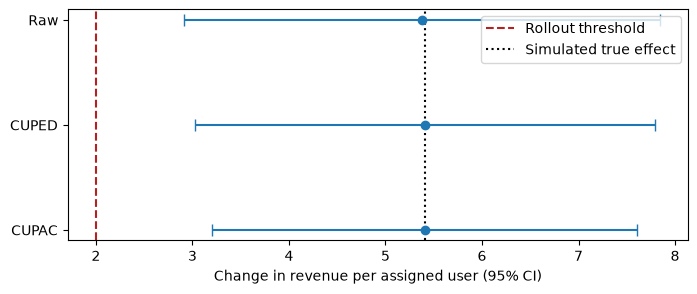

In [9]:
# Local presentation check (pandas and Matplotlib). Only three report rows.
import matplotlib.pyplot as plt

effect_columns = ["difference", "ci lower", "ci upper"]
comparison = pd.DataFrame.from_dict(effects, orient="index")[effect_columns]
comparison["CI width"] = comparison["ci upper"] - comparison["ci lower"]
comparison["variance reduction (%)"] = comparison.index.map(variance_reduction)
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 3))
estimate = comparison["difference"]
ax.errorbar(
    estimate,
    comparison.index,
    xerr=[estimate - comparison["ci lower"], comparison["ci upper"] - estimate],
    fmt="o",
    capsize=4,
)
ax.axvline(rollout_threshold, color="firebrick", linestyle="--", label="Rollout threshold")
ax.axvline(true_revenue_effect, color="black", linestyle=":", label="Simulated true effect")
ax.set_xlabel("Change in revenue per assigned user (95% CI)")
ax.invert_yaxis()
ax.legend()
plt.show()

<a id="make-decision"></a>

## 4. Apply the decision rule

Suppose CUPED was chosen for the primary decision before launch. Use its
interval to check the rollout threshold. Keep the raw and CUPAC estimates
as comparisons for the same effect. Choosing the estimator after seeing
which result supports rollout would change the decision procedure.

In [10]:
primary = cuped_revenue
decision = (
    "The revenue criterion for rollout is met."
    if primary["ci lower"] > rollout_threshold
    else "The revenue criterion for rollout has not been established."
)
print(
    f"CUPED estimate: {primary['difference']:.2f} per user "
    f"(95% CI {primary['ci lower']:.2f} to {primary['ci upper']:.2f})."
)
print(decision)
print(f"Known effect in this simulation: {true_revenue_effect:.2f} per user.")

CUPED estimate: 5.41 per user (95% CI 3.03 to 7.79).
The revenue criterion for rollout is met.
Known effect in this simulation: 5.41 per user.
